# "ReadyNow!" FEMA Emergency Preparedness & Response Multi-Agent System

> 📐 **Architecture Diagram Note:** A full visual **System Architecture Diagram** (with high-resolution **PNG** and scalable **SVG** download buttons, plus a component summary table) is located at the **very bottom of this notebook (Step 7)**.

## Project Overview
This notebook demonstrates the end-to-end design, local simulation, cloud packaging, and deployment of **"ReadyNow!"**—an enterprise multi-agent emergency preparedness and disaster response assistant developed for the **Federal Emergency Management Agency (FEMA)** using the **Google Agent Development Kit (ADK)** and **Vertex AI Agent Engine**.

ReadyNow! provides citizens and emergency managers with:
1. **Real-time Disaster Situational Awareness:** Live severe weather, hurricane/storm tracks, and National Weather Service forecasts.
2. **Emergency Preparedness & Guidance:** Verified survival checklists, kit planning, and authoritative advice based on FEMA.gov, CDC, and Red Cross protocols.
3. **Evacuation Assistance & Route Planning:** Waypoint geocoding, driving route calculations, and safe corridor suggestions.
4. **Audit Logging & Safety Guardrails:** Automated interaction auditing and input validation guardrails to ensure life-safety focus.

---

## System Architecture & Workflow Hierarchy
The application is coordinated by the `ready_now_root_agent` triage coordinator, which validates user queries and delegates to specialized emergency agents:

```text
                                [ ready_now_root_agent ]
                                (Triage, Guardrails, Audit)
                                            │
         ────────────────────────┴────────────────────────────────────┐
         │                              │                                     │                                  │
         ┰                              ┰                                     ┰                                  ┰
  [ greeter_agent ]           [ weather_hazard_agent ]             [ evacuation_routing_agent ]        [ preparedness_team ]
  (Intake & Briefing)         (OSM Geocode + NWS Forecast)         (Safe Corridors & Distance)         (Sequential 3-Step Pipeline)
                                                                                                                 │
                                                ──────────────────────────────┴──────────────────────────────┐
                                                │                             │                              │
                                                ┰                             ┰                              ┰
                                       [ fema_search_agent ]       [ safety_critique_agent ]      [ actionable_refine_agent ]
                                       (Google Search Tool)        (Protocol & Fact Review)       (Refined Action Checklist)
```

- **`ready_now_root_agent`**: Central triage orchestrator with built-in input validation guardrails and audit callback hooks.
- **`greeter_agent`**: Welcomes citizens and outlines available emergency preparedness and response resources.
- **`weather_hazard_agent`**: Retrieves live NWS severe weather alerts and localized forecasts using OpenStreetMap coordinates.
- **`evacuation_routing_agent`**: Calculates turn-by-turn driving distances, travel times, and safe evacuation paths using the OpenStreetMap/OSRM routing engine.
- **`preparedness_team`**: A sequential 3-step safety pipeline:
  1. **`fema_search_agent`**: Gathers authoritative guidelines using Google Search via an isolated `AgentTool` worker.
  2. **`safety_critique_agent`**: Verifies recommendations against FEMA, Red Cross, and CDC safety criteria.
  3. **`actionable_refine_agent`**: Synthesizes verified advice into an emergency-ready, priority-ordered action plan.

---

## Notebook Navigation & Execution Guide

1. **Step 1 & 2: Environment Setup, Tools, Audit Logging, & FEMA Agent Architecture**
   Configures regional Vertex AI (`us-central1`), initializes the staging bucket, registers custom tools (Geocoding, NWS, OSRM Routing, Audit Callbacks, Guardrails), and compiles the multi-agent hierarchy.
2. **Step 3: Local Simulation & Comprehensive Scenario Testing**
   Tests all agent pathways locally via `AdkApp(agent=ready_now_root_agent)`: greeting, severe weather forecast, evacuation routing, 3-step preparedness workflow, and off-topic guardrail rejection.
3. **Step 4a: Cloud Deployment to Vertex AI Agent Engine**
   Packages and provisions the containerized service on Vertex AI Agent Engine using `agent_engines.create(...)`.
4. **Step 4b: Remote Managed Cloud Endpoint Verification**
   Directly streams live requests against the cloud endpoint (`remote_agent.stream_query`).
5. **Step 5: Visual Results Dashboard & Interactive Emergency Chat**
   Provides a live status dashboard, direct links to Google Cloud Console and Cloud Logging, and an interactive chat widget.
6. **Step 6: Resource Cleanup**
   Utility cell to list and delete deployed Agent Engine instances after evaluation.
7. **Step 7: System Architecture Diagram & High-Res PNG/SVG Export (Bottom of Notebook)**
   Provides the architectural component table and generates downloadable 300-DPI PNG and scalable vector SVG diagrams of the ReadyNow! solution.

---
## Step 1 & 2: Environment Setup, Tools, Guardrails & Multi-Agent Architecture

### Overview
This section initializes the cloud environment and constructs the **ReadyNow!** FEMA multi-agent system:
1. **Vertex AI & Cloud Storage Setup (`Step 1`)**: Sets up the Google Cloud Project (`qwiklabs-gcp-01-6d489226baf6`), regional location (`us-central1`), and regional staging bucket for managed agent deployment.
2. **Custom FEMA Tools & Audit Callbacks**:
   - **Geocoding & NWS Forecast**: OpenStreetMap Nominatim geocoding and National Weather Service forecast integration.
   - **Evacuation Routing Tool**: Free OpenStreetMap/OSRM driving route computation for distances, travel times, and corridor advice.
   - **Audit Callback Logger**: Captures structured logs of all interactions, routing transfers, and tool executions.
   - **FEMA Guardrail Tool**: Validates input scope to ensure requests remain focused on safety, weather, routing, and emergency preparedness.
3. **Multi-Agent Hierarchy (`Step 2`)**: Compiles `ready_now_root_agent` with specialized sub-agents and the 3-step sequential workflow team.

In [44]:
# ============================================================
# FEMA READYNOW! MULTI-AGENT EMERGENCY PREPAREDNESS SYSTEM
# Step 1: Initialize Regional Vertex AI & Cloud Storage
# Step 2: Define Tools, Audit Callbacks, Guardrails & ADK Hierarchy
# ============================================================
import datetime
import json
import os
from typing import Any, Dict, List, Optional
import warnings

from google.adk.agents.llm_agent import LlmAgent
from google.adk.agents.sequential_agent import SequentialAgent
from google.adk.tools import google_search
from google.adk.tools.agent_tool import AgentTool
from google.cloud import storage
import requests
import vertexai

# Disable LiteLLM MCP subsystem
os.environ["LITELLM_DISABLE_MCP"] = "true"

# Suppress experimental JSON schema warnings
warnings.filterwarnings(
    "ignore",
    message=".*JSON_SCHEMA_FOR_FUNC_DECL is enabled.*",
)

# ------------------------------------------------------------
# STEP 1: INITIALIZE VERTEX AI FOR AGENT ENGINE
# ------------------------------------------------------------
PROJECT_ID_LIST = !gcloud config get-value project
PROJECT_ID = PROJECT_ID_LIST[0] if PROJECT_ID_LIST else ""
if PROJECT_ID == "(unset)" or not PROJECT_ID:
    PROJECT_ID = "qwiklabs-gcp-01-6d489226baf6"

LOCATION = "us-central1"
BUCKET_NAME = f"agent-engine-staging-{PROJECT_ID}"
STAGING_BUCKET = f"gs://{BUCKET_NAME}"

os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_CLOUD_QUOTA_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "1"
os.environ["GOOGLE_CLOUD_LOCATION"] = LOCATION
os.environ["ADK_SUPPRESS_GEMINI_LITELLM_WARNINGS"] = "true"

storage_client = storage.Client(project=PROJECT_ID)
bucket = storage_client.bucket(BUCKET_NAME)
if not bucket.exists():
    print(f"Creating staging bucket: {STAGING_BUCKET} in {LOCATION}...")
    storage_client.create_bucket(bucket, location=LOCATION)
else:
    print(f"Using existing staging bucket: {STAGING_BUCKET}")

vertexai.init(
    project=PROJECT_ID,
    location=LOCATION,
    staging_bucket=STAGING_BUCKET,
)

print(f"Vertex AI initialized successfully:")
print(f"  Project ID     : {PROJECT_ID}")
print(f"  Location       : {LOCATION}")
print(f"  Staging Bucket : {STAGING_BUCKET}")

# ------------------------------------------------------------
# STEP 2: AUDIT LOGGING & CUSTOM TOOLS
# ------------------------------------------------------------

class AuditLogger:
    """In-memory structured audit logger for tracking agent interactions."""
    def __init__(self):
        self.records: List[Dict[str, Any]] = []

    def log(self, event_type: str, details: Dict[str, Any]) -> None:
        entry = {
            "timestamp": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            "event_type": event_type,
            "details": details,
        }
        self.records.append(entry)

    def get_summary(self) -> List[Dict[str, Any]]:
        return self.records[-10:]

audit_logger = AuditLogger()

def geocode_place_free(address: str) -> str:
    """Geocode an address or city into latitude and longitude coordinates."""
    base_url = "https://nominatim.openstreetmap.org/search"
    params = {"q": address, "format": "json", "limit": 1}
    headers = {
        "User-Agent": "FemaReadyNowApp/1.0 (emergency-preparedness@fema.gov)"
    }
    try:
        response = requests.get(base_url, params=params, headers=headers, timeout=10)
        response.raise_for_status()
        data = response.json()
        if data:
            coords = f"{data[0]['lat']}, {data[0]['lon']}"
            audit_logger.log("tool_geocode", {"query": address, "coords": coords})
            return coords
    except Exception as e:
        audit_logger.log("tool_geocode_error", {"query": address, "error": str(e)})
    return "Error: Location not found."

def get_nws_forecast(latitude: float, longitude: float) -> str:
    """Retrieve the official National Weather Service (NWS) forecast and severe alerts."""
    headers = {
        "User-Agent": "FemaReadyNowApp/1.0 (emergency-preparedness@fema.gov)"
    }
    points_url = f"https://api.weather.gov/points/{latitude},{longitude}"
    try:
        points_response = requests.get(points_url, headers=headers, timeout=10)
        points_response.raise_for_status()
        props = points_response.json()["properties"]
        forecast_url = props["forecast"]
        forecast_response = requests.get(forecast_url, headers=headers, timeout=10)
        forecast_response.raise_for_status()
        periods = forecast_response.json()["properties"]["periods"]
        formatted = []
        for period in periods[:3]:
            formatted.append(
                f"{period['name']}: {period['temperature']}°"
                f"{period['temperatureUnit']}, {period['shortForecast']}. "
                f"Wind: {period.get('windSpeed', 'N/A')} {period.get('windDirection', '')}."
            )
        result = "\n\n".join(formatted)
        audit_logger.log("tool_nws_forecast", {"lat": latitude, "lon": longitude})
        return result
    except Exception as e:
        audit_logger.log("tool_nws_error", {"error": str(e)})
        return f"Error retrieving NWS weather forecast: {e}"

def calculate_evacuation_route(origin: str, destination: str) -> str:
    """Calculate driving distance, travel duration, and route directions between two locations using OpenStreetMap OSRM."""
    origin_coords_str = geocode_place_free(origin)
    dest_coords_str = geocode_place_free(destination)
    if "Error" in origin_coords_str or "Error" in dest_coords_str:
        return f"Error: Unable to geocode route points: Origin='{origin}' ({origin_coords_str}), Destination='{destination}' ({dest_coords_str})"
    try:
        o_lat, o_lon = [float(x.strip()) for x in origin_coords_str.split(",")]
        d_lat, d_lon = [float(x.strip()) for x in dest_coords_str.split(",")]
        osrm_url = f"https://router.project-osrm.org/route/v1/driving/{o_lon},{o_lat};{d_lon},{d_lat}?overview=false"
        headers = {"User-Agent": "FemaReadyNowApp/1.0 (emergency-preparedness@fema.gov)"}
        res = requests.get(osrm_url, headers=headers, timeout=10)
        res.raise_for_status()
        route_data = res.json()
        if route_data.get("code") == "Ok" and route_data.get("routes"):
            route = route_data["routes"][0]
            distance_miles = round(route["distance"] * 0.000621371, 1)
            duration_mins = round(route["duration"] / 60)
            hours, mins = divmod(duration_mins, 60)
            time_str = f"{hours} hr {mins} min" if hours > 0 else f"{mins} min"
            route_summary = (
                f"Evacuation Route Summary:\n"
                f"- Origin: {origin} ({o_lat:.4f}, {o_lon:.4f})\n"
                f"- Destination: {destination} ({d_lat:.4f}, {d_lon:.4f})\n"
                f"- Driving Distance: {distance_miles} miles\n"
                f"- Estimated Travel Time: {time_str} (normal traffic flow)\n"
                f"- Safety Note: Keep at least a half tank of fuel, carry a paper map, and follow local DOT emergency contraflow directions."
            )
            audit_logger.log("tool_evacuation_route", {"origin": origin, "destination": destination, "miles": distance_miles})
            return route_summary
    except Exception as e:
        audit_logger.log("tool_evacuation_error", {"error": str(e)})
    return f"Unable to calculate driving route between {origin} and {destination}. Please rely on local radio and emergency DOT signage."

def validate_emergency_scope(user_query: str) -> str:
    """Validate whether the user's query falls within the scope of FEMA ReadyNow! emergency preparedness, weather, disaster response, or routing."""
    off_topic_keywords = ["stock market", "movie", "celebrity", "crypto", "fantasy football", "gossip", "video game"]
    query_lower = user_query.lower()
    for kw in off_topic_keywords:
        if kw in query_lower:
            return (
                f"Scope Guardrail Triggered: The inquiry mentions '{kw}', which is outside FEMA ReadyNow!'s "
                f"emergency mandate. ReadyNow! is dedicated exclusively to disaster preparedness, severe weather "
                f"warnings, evacuation routing, and life-safety guidance."
            )
    return "Scope Valid: Request is relevant to emergency preparedness or disaster assistance."

# ------------------------------------------------------------
# STEP 2 CONTINUED: DEFINE FEMA MULTI-AGENT HIERARCHY
# ------------------------------------------------------------
MODEL_NAME = "gemini-2.5-flash"

greeter_agent = LlmAgent(
    name="greeter_agent",
    model=MODEL_NAME,
    description="Welcomes citizens and introduces FEMA ReadyNow! emergency capabilities.",
    instruction=(
        "You are the FEMA ReadyNow! Greeting and Public Information Agent. "
        "Warmly welcome citizens with calm, reassuring authority. Introduce yourself as FEMA ReadyNow! "
        "Explain your 4 core services:\n"
        "1. Severe Weather Alerts & NWS Forecasts\n"
        "2. Evacuation Corridor & Driving Route Planning\n"
        "3. Official Disaster Preparedness & Safety Checklists (Search, Critique & Refine Team)\n"
        "4. Triage and Emergency Guidance.\n"
        "Remind users: For active life-threatening emergencies, always dial 911 immediately."
    ),
)

weather_hazard_agent = LlmAgent(
    name="weather_hazard_agent",
    model=MODEL_NAME,
    description="Retrieves live National Weather Service (NWS) forecasts, storm alerts, and severe weather warnings.",
    instruction=(
        "You are the FEMA Weather and Natural Hazard Specialist. When a citizen asks about weather, "
        "storms, hurricanes, or severe conditions, use your geocode_place_free and get_nws_forecast tools. "
        "Provide a concise, safety-oriented weather report emphasizing any hazardous conditions (winds, storms, heat, freezes). "
        "Always explicitly state the city, state, and coordinates in your response."
    ),
    tools=[geocode_place_free, get_nws_forecast],
)

evacuation_routing_agent = LlmAgent(
    name="evacuation_routing_agent",
    model=MODEL_NAME,
    description="Calculates evacuation routes, travel distances, driving times, and transit advice during disasters.",
    instruction=(
        "You are the FEMA Evacuation and Transit Planning Agent. When citizens need to evacuate, find shelter, "
        "or calculate distances to safe zones, use your calculate_evacuation_route tool. "
        "Provide practical, life-safety guidance: highlight travel distance, estimated duration, emergency fuel preparedness, "
        "and remind evacuees to monitor local Department of Transportation (DOT) updates for road closures and contraflow lanes."
    ),
    tools=[calculate_evacuation_route, geocode_place_free],
)

fema_search_worker = LlmAgent(
    name="fema_search_worker",
    model=MODEL_NAME,
    description="Searches authoritative federal sources (FEMA.gov, Ready.gov, CDC, Red Cross) for emergency protocols.",
    instruction=(
        "Use the google_search tool to find accurate, authoritative disaster preparedness protocols, "
        "emergency kit checklists, flood/hurricane survival guidelines, or emergency response instructions."
    ),
    tools=[google_search],
)

fema_search_agent = LlmAgent(
    name="fema_search_agent",
    model=MODEL_NAME,
    description="Step 1: Searches authoritative disaster preparedness resources to answer citizen questions.",
    instruction=(
        "You are Step 1 of the Preparedness Team. Use your `fema_search_worker` tool to locate verified emergency guidelines "
        "and disaster protocols. Draft a thorough, fact-based initial preparedness recommendation for the user's inquiry."
    ),
    tools=[AgentTool(agent=fema_search_worker)],
    output_key="initial_preparedness_draft",
)

safety_critique_agent = LlmAgent(
    name="safety_critique_agent",
    model=MODEL_NAME,
    description="Step 2: Critiques and reviews the initial safety draft against FEMA and life-safety standards.",
    instruction=(
        "You are Step 2 of the Preparedness Team. Review the initial draft:\n{initial_preparedness_draft}\n\n"
        "Evaluate the recommendations against strict FEMA/Ready.gov standards:\n"
        "1. Are life-critical items included (water: 1 gal/person/day for 3 days, non-perishable food, flashlight, first aid, medicines)?\n"
        "2. Are hazardous actions avoided (e.g., generator indoors, walking through moving floodwaters)?\n"
        "3. Is the guidance direct, actionable, and structured for quick reading under stress?\n"
        "Provide 2-3 specific safety critiques to refine the output."
    ),
    output_key="safety_critique_feedback",
)

actionable_refine_agent = LlmAgent(
    name="actionable_refine_agent",
    model=MODEL_NAME,
    description="Step 3: Synthesizes draft and safety critiques into a clear, prioritized FEMA action checklist.",
    instruction=(
        "You are Step 3 of the Preparedness Team. Take the initial draft:\n{initial_preparedness_draft}\n\n"
        "And the safety critique:\n{safety_critique_feedback}\n\n"
        "Produce the definitive FEMA ReadyNow! emergency checklist. Structure the final output with:\n"
        "- ⚠️ **Immediate Action Summary**\n"
        "- 📦 **Essential Supplies & Kit Checklist**\n"
        "- 🟢 **Step-by-Step Preparedness Procedures**\n"
        "- 📞 **Key Emergency Contacts** (e.g., 911, local emergency management, FEMA: 1-800-621-3362).\n"
        "Keep the tone calm, authoritative, and easy to read during an emergency."
    ),
    output_key="final_emergency_guide",
)

preparedness_team = SequentialAgent(
    name="preparedness_team",
    description="Sequential 3-step pipeline (Search -> Safety Critique -> Actionable Refine) for disaster preparedness.",
    sub_agents=[fema_search_agent, safety_critique_agent, actionable_refine_agent],
)

ready_now_root_agent = LlmAgent(
    name="ready_now_root_agent",
    model=MODEL_NAME,
    description="FEMA ReadyNow! Root Coordinator that validates query scope, logs audit events, and delegates to specialized agents.",
    instruction=(
        "You are the FEMA ReadyNow! Root Coordinator Agent. You are the frontline intake and triage officer for emergency preparedness.\n\n"
        "Operational Protocol:\n"
        "1. **Input Guardrail Check:** If the citizen's query is clearly off-topic (e.g. pop culture, fantasy sports, gossip), "
        "use `validate_emergency_scope` or politely explain that ReadyNow! is reserved exclusively for disaster preparedness, safety, weather, and evacuation.\n"
        "2. **Sub-Agent Routing:**\n"
        "   - Greetings, system capabilities, or 'who are you?' → delegate to `greeter_agent`.\n"
        "   - Weather forecasts, hurricane/storm tracks, freeze/heat advisories → delegate to `weather_hazard_agent`.\n"
        "   - Evacuation routes, driving directions between safe zones, transit planning → delegate to `evacuation_routing_agent`.\n"
        "   - Disaster planning, supply kits, flood/wildfire/earthquake preparedness, FEMA checklists → delegate to `preparedness_team`.\n"
        "3. Always maintain a reassuring, professional, and safety-first tone."
    ),
    tools=[validate_emergency_scope],
    sub_agents=[greeter_agent, weather_hazard_agent, evacuation_routing_agent, preparedness_team],
)

print("\nFEMA ReadyNow! Multi-Agent Hierarchy defined successfully: ready_now_root_agent is ready.")

Using existing staging bucket: gs://agent-engine-staging-qwiklabs-gcp-01-6d489226baf6
Vertex AI initialized successfully:
  Project ID     : qwiklabs-gcp-01-6d489226baf6
  Location       : us-central1
  Staging Bucket : gs://agent-engine-staging-qwiklabs-gcp-01-6d489226baf6

FEMA ReadyNow! Multi-Agent Hierarchy defined successfully: ready_now_root_agent is ready.


/tmp/ipykernel_4818/46763477.py:284: DeprecationWarning: SequentialAgent is deprecated in favor of Workflow and will be removed in a future version. Workflow cannot yet be used as an LlmAgent sub-agent.
  preparedness_team = SequentialAgent(


---
## Step 3: Local Simulation & Comprehensive Scenario Testing

### Overview
Before deploying the multi-agent system to Vertex AI Agent Engine, this step verifies all five critical pathways locally using `vertexai.preview.reasoning_engines.AdkApp(agent=ready_now_root_agent)`:

1. **Greeting & Triage**: Confirms `ready_now_root_agent` routes intake requests to `greeter_agent`.
2. **Weather Hazard Assessment**: Evaluates real-time NWS severe weather querying for storm-prone regions via `weather_hazard_agent`.
3. **Evacuation Corridor Calculation**: Evaluates route distance, travel duration, and corridor directions via `evacuation_routing_agent`.
4. **3-Step Preparedness Pipeline**: Runs the multi-agent workflow (`fema_search_agent` → `safety_critique_agent` → `actionable_refine_agent`) to produce a verified disaster plan.
5. **Input Validation Guardrail**: Verifies off-topic inquiries are safely flagged and rejected.
6. **Audit Trail Inspection**: Displays recorded interactions and tool calls from `audit_logger`.

In [45]:
# ============================================================
# STEP 3: LOCAL SIMULATION & COMPREHENSIVE SCENARIO TESTING
# Wraps ready_now_root_agent in AdkApp and tests all agent routes
# ============================================================
from vertexai.preview.reasoning_engines import AdkApp

# Instantiate local ADK application
app = AdkApp(agent=ready_now_root_agent)

def run_scenario(title: str, query: str):
    print("=" * 80)
    print(f"SCENARIO: {title}")
    print(f"User Query: \"{query}\"")
    print("=" * 80)
    last_response = None
    for event in app.stream_query(user_id="fema-local-tester", message=query):
        if not isinstance(event, dict):
            continue
        author = event.get("author", "agent")
        content = event.get("content", {})
        for part in content.get("parts", []):
            if "function_call" in part:
                fc = part["function_call"]
                print(f"  -> [{author}] called '{fc.get('name')}' with args {fc.get('args')}")
            if "text" in part and part["text"].strip():
                last_response = part["text"]
    print("\n--- Final Agent Response ---")
    print(last_response if last_response else "(No text generated)")
    print("\n")

# Test 1: Greeter & Public Intake
run_scenario(
    "1. Public Intake & Capabilities",
    "Hello! What emergency services can ReadyNow! assist me with?",
)

# Test 2: Weather & Hazard Specialist
run_scenario(
    "2. Severe Weather & Hazard Monitoring",
    "What is the current severe weather forecast for Tampa, Florida?",
)

# Test 3: Evacuation Routing & Corridor Analysis
run_scenario(
    "3. Evacuation Route & Transit Planning",
    "I need an evacuation driving route from Tampa, FL to Orlando, FL. How far is it and how long will it take?",
)

# Test 4: 3-Step Preparedness Sequential Pipeline
run_scenario(
    "4. 3-Step Preparedness Pipeline (Search -> Safety Critique -> Refine)",
    "What specific survival supplies and procedures should I prepare for a Category 4 hurricane?",
)

# Test 5: Input Validation Guardrail
run_scenario(
    "5. Scope Guardrail Enforcement (Off-Topic Rejection)",
    "Who won the celebrity fantasy football movie awards last night?",
)

# Test 6: Audit Log Summary
print("=" * 80)
print("AUDIT LOGGER SUMMARY (Recorded System Interactions)")
print("=" * 80)
for log in audit_logger.get_summary():
    print(f"[{log['timestamp']}] {log['event_type']}: {log['details']}")

SCENARIO: 1. Public Intake & Capabilities
User Query: "Hello! What emergency services can ReadyNow! assist me with?"


/usr/local/lib/python3.12/dist-packages/vertexai/preview/reasoning_engines/templates/adk.py:1005: UserWarning: [EXPERIMENTAL] InMemoryCredentialService: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  self._tmpl_attrs["credential_service"] = InMemoryCredentialService()
/usr/local/lib/python3.12/dist-packages/google/adk/auth/credential_service/in_memory_credential_service.py:33: UserWarning: [EXPERIMENTAL] BaseCredentialService: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  super().__init__()


  -> [ready_now_root_agent] called 'transfer_to_agent' with args {'agent_name': 'greeter_agent'}

--- Final Agent Response ---
Hello! I'm FEMA ReadyNow!, your Greeting and Public Information Agent. I'm here to help you understand our emergency capabilities.

We offer four core services to assist you:

1.  **Severe Weather Alerts & NWS Forecasts:** We provide real-time updates and forecasts from the National Weather Service to keep you informed about severe weather conditions.
2.  **Evacuation Corridor & Driving Route Planning:** In the event of a disaster, we can help you plan the safest and most efficient evacuation routes.
3.  **Official Disaster Preparedness & Safety Checklists:** Our Preparedness Team can provide, critique, and refine disaster preparedness and safety checklists to ensure you're ready for any situation.
4.  **Triage and Emergency Guidance:** We offer initial guidance and support during emergencies to help you take appropriate action.

Please remember, for active lif

---
## Step 4a: Deploy ReadyNow! to Vertex AI Agent Engine

### Overview
This step packages our `AdkApp(agent=ready_now_root_agent)` application and provisions a fully managed container service on **Vertex AI Agent Engine** using `agent_engines.create(...)`.

### Execution Instructions
1. Run the code cell below to deploy the agent to the `us-central1` region.
2. **Expected Runtime:** Provisioning the managed container runtime typically takes **3 to 5 minutes**.
3. Upon completion, the cell displays:
   - **Agent Resource Name:** `projects/.../locations/us-central1/reasoningEngines/...`
   - **Google Cloud Console URL:** Direct link to inspect the deployed agent runtime and live logs.

In [46]:
# ============================================================
# Step 4a: Deploy FEMA ReadyNow! to Vertex AI Agent Engine
# Uses `agent_engines.create(app, requirements=[...])`
# ============================================================
import importlib
import importlib.metadata
import google.protobuf.json_format as _json_format
from google.protobuf.json_format import ParseError
from vertexai import agent_engines

# Ensure protobuf parser gracefully handles all server response fields
importlib.reload(_json_format)
_real_parse = _json_format.Parse
_real_parse_dict = _json_format.ParseDict

def _safe_parse(text, message, ignore_unknown_fields=True, *args, **kwargs):
    return _real_parse(text, message, True, *args, **kwargs)

def _safe_parse_dict(js_dict, message, ignore_unknown_fields=True, *args, **kwargs):
    return _real_parse_dict(js_dict, message, True, *args, **kwargs)

_json_format.Parse = _safe_parse
_json_format.ParseDict = _safe_parse_dict

adk_version = importlib.metadata.version("google-adk")
aiplatform_version = importlib.metadata.version("google-cloud-aiplatform")
print(f"Local google-adk version              : {adk_version}")
print(f"Local google-cloud-aiplatform version : {aiplatform_version}")

DISPLAY_NAME = "fema-readynow-emergency-agent-v1"

existing_agents = [
    engine
    for engine in agent_engines.list()
    if getattr(engine, "display_name", "") == DISPLAY_NAME
]

if existing_agents:
    remote_agent = existing_agents[-1]
    print(f"Found existing deployed agent '{DISPLAY_NAME}' on Agent Platform!")
else:
    print(f"Deploying AdkApp ('{DISPLAY_NAME}') to Vertex AI Agent Engine...")
    print("Note: Cloud container build and deployment takes ~3-5 minutes.\n")
    try:
        remote_agent = agent_engines.create(
            app,
            display_name=DISPLAY_NAME,
            description=(
                "FEMA ReadyNow! Multi-Agent Emergency Preparedness System with "
                "weather hazards, evacuation routing, and 3-step safety verification."
            ),
            requirements=[
                f"google-cloud-aiplatform[agent_engines,adk]=={aiplatform_version}",
                f"google-adk=={adk_version}",
                "requests",
            ],
        )
    except ParseError:
        print("Note: Protobuf ParseError handled; retrieving newly deployed agent...")
        remote_agent = [
            engine
            for engine in agent_engines.list()
            if getattr(engine, "display_name", "") == DISPLAY_NAME
        ][-1]

print("\n" + "=" * 75)
print("DEPLOYMENT SUCCESSFUL!")
print("=" * 75)
print(f"Display Name  : {getattr(remote_agent, 'display_name', DISPLAY_NAME)}")
print(f"Resource Name : {remote_agent.resource_name}")
print(
    "GCP Console   : "
    f"https://console.cloud.google.com/vertex-ai/agents/agent-engines?project={PROJECT_ID}"
)

INFO:vertexai.agent_engines:Identified the following requirements: {'cloudpickle': '3.1.2', 'pydantic': '2.14.1', 'google-cloud-aiplatform': '2.5.0'}
INFO:vertexai.agent_engines:The following requirements are appended: {'cloudpickle==3.1.2', 'pydantic==2.14.1'}
INFO:vertexai.agent_engines:The final list of requirements: ['google-cloud-aiplatform[agent_engines,adk]==2.5.0', 'google-adk==2.7.0', 'requests', 'cloudpickle==3.1.2', 'pydantic==2.14.1']


Local google-adk version              : 2.7.0
Local google-cloud-aiplatform version : 2.5.0
Deploying AdkApp ('fema-readynow-emergency-agent-v1') to Vertex AI Agent Engine...
Note: Cloud container build and deployment takes ~3-5 minutes.



INFO:vertexai.agent_engines:Using bucket agent-engine-staging-qwiklabs-gcp-01-6d489226baf6
INFO:vertexai.agent_engines:Wrote to gs://agent-engine-staging-qwiklabs-gcp-01-6d489226baf6/agent_engine/agent_engine.pkl
INFO:vertexai.agent_engines:Writing to gs://agent-engine-staging-qwiklabs-gcp-01-6d489226baf6/agent_engine/requirements.txt
INFO:vertexai.agent_engines:Creating in-memory tarfile of extra_packages
INFO:vertexai.agent_engines:Writing to gs://agent-engine-staging-qwiklabs-gcp-01-6d489226baf6/agent_engine/dependencies.tar.gz
INFO:vertexai.agent_engines:Creating AgentEngine
INFO:vertexai.agent_engines:Create AgentEngine backing LRO: projects/162821977671/locations/us-central1/reasoningEngines/7786427162461995008/operations/5886172221545644032
INFO:vertexai.agent_engines:View progress and logs at https://console.cloud.google.com/logs/query?project=qwiklabs-gcp-01-6d489226baf6
INFO:vertexai.agent_engines:AgentEngine created. Resource name: projects/162821977671/locations/us-central1


DEPLOYMENT SUCCESSFUL!
Display Name  : fema-readynow-emergency-agent-v1
Resource Name : projects/162821977671/locations/us-central1/reasoningEngines/7786427162461995008
GCP Console   : https://console.cloud.google.com/vertex-ai/agents/agent-engines?project=qwiklabs-gcp-01-6d489226baf6


---
## Step 4b: Test Deployed Remote ReadyNow! Agent via Cloud Endpoint

### Overview
This step invokes `remote_agent.stream_query(...)` directly against the live managed cloud endpoint in **Vertex AI Agent Engine**.

### Tests Executed
1. **3-Step Preparedness Workflow:** Sends a disaster preparation query handled sequentially by `fema_search_agent` → `safety_critique_agent` → `actionable_refine_agent`.
2. **Evacuation Routing & Corridor Test:** Verifies cloud execution of the `calculate_evacuation_route` tool.
3. **Severe Weather Hazard Test:** Verifies live execution of custom Python tools (`geocode_place_free` and `get_nws_forecast`) running inside the cloud container.

In [47]:
# ============================================================
# Step 4b: Test Deployed Remote Agent via Managed Cloud Endpoint
# Uses remote_agent.stream_query(...) to test the live deployment
# ============================================================
import collections
import importlib
import json
import google.api_core.rest_streaming as _rest_streaming
import google.protobuf.json_format as _json_format
from vertexai import agent_engines

# 1. Cleanly restore json_format and apply idempotent ignore_unknown_fields wrapper
importlib.reload(_json_format)
_real_parse = _json_format.Parse
_real_parse_dict = _json_format.ParseDict

def _safe_parse(text, message, ignore_unknown_fields=True, *args, **kwargs):
    return _real_parse(text, message, True, *args, **kwargs)

def _safe_parse_dict(js_dict, message, ignore_unknown_fields=True, *args, **kwargs):
    return _real_parse_dict(js_dict, message, True, *args, **kwargs)

_json_format.Parse = _safe_parse
_json_format.ParseDict = _safe_parse_dict

# 2. Compatibility fix for google-api-core REST streaming
def _ndjson_next(self):
    while not getattr(self, "_ready_objs", None):
        if not hasattr(self, "_ready_objs"):
            self._ready_objs = collections.deque()
        if not hasattr(self, "_ndjson_buf"):
            self._ndjson_buf = ""
        try:
            chunk = next(self._response_itr)
            if isinstance(chunk, bytes):
                chunk = chunk.decode("utf-8")
            self._ndjson_buf += chunk
            lines = self._ndjson_buf.split("\n")
            self._ndjson_buf = lines.pop()
            for line in lines:
                line = line.strip()
                if line:
                    self._ready_objs.append(line)
        except StopIteration:
            rem = getattr(self, "_ndjson_buf", "").strip()
            self._ndjson_buf = ""
            if rem:
                self._ready_objs.append(rem)
            if not self._ready_objs:
                raise
    raw = self._ready_objs.popleft()
    if hasattr(self, "_response_message_cls") and self._response_message_cls is not None:
        try:
            return json.loads(raw)
        except Exception:
            pass
    return raw

_rest_streaming.ResponseIterator.__next__ = _ndjson_next

print("=" * 75)
print("VERIFYING DEPLOYED AGENTS ON AGENT PLATFORM (agent_engines.list)")
print("=" * 75)
deployed_engines = list(agent_engines.list())
for engine in deployed_engines:
    print(f"  - Display Name  : {getattr(engine, 'display_name', 'N/A')}")
    print(f"    Resource Name : {engine.resource_name}")

# Select the newly deployed ReadyNow agent
readynow_engines = [
    e for e in deployed_engines
    if "readynow" in getattr(e, "display_name", "").lower()
]
remote_agent = readynow_engines[-1] if readynow_engines else deployed_engines[-1]
print(f"\nTesting remote_agent: {remote_agent.resource_name}")

# ------------------------------------------------------------
# Stream query from the deployed remote_agent
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("REMOTE TEST 1: 3-Step Preparedness Team (Search -> Critique -> Refine)")
print("Prompt: 'What emergency supplies and actions are recommended for sudden flash flooding?'")
print("=" * 75)

final_preparedness_answer = None
for event in remote_agent.stream_query(
    user_id="fema-cloud-tester",
    message="What emergency supplies and actions are recommended for sudden flash flooding?",
):
    print(event)
    content = event.get("content", {}) if isinstance(event, dict) else {}
    for part in content.get("parts", []):
        if "text" in part:
            final_preparedness_answer = part["text"]

if final_preparedness_answer:
    print("\n--- Final Refined Guide from Deployed Remote Agent ---")
    print(final_preparedness_answer)

# ------------------------------------------------------------
# Additional Remote Tests: Evacuation Routing & Weather Forecast
# ------------------------------------------------------------
additional_prompts = [
    ("Evacuation Routing", "What is the driving route and distance to evacuate from Miami, FL to Fort Myers, FL?"),
    ("Severe Weather Hazard", "What is the current severe weather forecast for New Orleans, LA?"),
]

last_remote_response = None
for label, prompt in additional_prompts:
    print("\n" + "=" * 75)
    print(f"REMOTE AGENT TEST: {label}")
    print(f"Prompt: '{prompt}'")
    print("=" * 75)
    last_text = None
    for event in remote_agent.stream_query(
        user_id="fema-cloud-tester",
        message=prompt,
    ):
        print(event)
        content = event.get("content", {}) if isinstance(event, dict) else {}
        for part in content.get("parts", []):
            if "text" in part:
                last_text = part["text"]
                last_remote_response = part["text"]
    if last_text:
        print(f"\n--- Final Response ({label}) ---")
        print(last_text)

Falling back to grpc since no async rest credentials were detected.


VERIFYING DEPLOYED AGENTS ON AGENT PLATFORM (agent_engines.list)
  - Display Name  : fema-readynow-emergency-agent-v1
    Resource Name : projects/162821977671/locations/us-central1/reasoningEngines/7786427162461995008

Testing remote_agent: projects/162821977671/locations/us-central1/reasoningEngines/7786427162461995008

REMOTE TEST 1: 3-Step Preparedness Team (Search -> Critique -> Refine)
Prompt: 'What emergency supplies and actions are recommended for sudden flash flooding?'
{'model_version': 'gemini-2.5-flash', 'content': {'parts': [{'function_call': {'id': 'adk-4da265ef-82ca-40c3-9351-b851df78dc7f', 'args': {'agent_name': 'preparedness_team'}, 'name': 'transfer_to_agent'}, 'thought_signature': 'AY89a1_03nycERb4DbLtS8P06tbsSzQY1afjZkul1UQpZDEo3dOC_oS3ejYLdpC9JYCmrKOJpubTbIbrQZ0D5-cvP6Wy2LRDJz6gfjx-vWk8jpSf8rMFS1WOAAKM79iEZyFFe0GUm0F_Us4ULZDE28tEut95XtWJbw8dAA5jyX0ZBPdxY23AK1UgaUJ0gMlcDte0P3EFwBEm2ivTnTAyhaTyxoApda4eYQuNz-Bpv6eUuX1_CNaW8ezo16vh5KpZFXMXY64dnawIFu6oTuOlfs_HhVc3Aefunb

---
## Step 5: FEMA Emergency Operations Dashboard & Interactive Chat

### Overview
This step provides:
1. A **Visual Operations Dashboard** showing cloud deployment details, resource metrics, and direct links to the Google Cloud Console and Cloud Logging.
2. An **Interactive Live Emergency Chat Widget** allowing evaluators to interact directly with the deployed ReadyNow! cloud agent in real time.

In [48]:
# ============================================================
# Step 5: Visual Results Dashboard & Interactive Chat
# Displays deployment metrics, console links, and live chat widget
# ============================================================
import html
from IPython.display import HTML, Markdown, display
import ipywidgets as widgets

console_list_url = (
    f"https://console.cloud.google.com/vertex-ai/agents/agent-engines"
    f"?project={PROJECT_ID}"
)
logs_url = (
    f"https://console.cloud.google.com/logs/query;query=resource.type%3D%22"
    f"aiplatform.googleapis.com%2FReasoningEngine%22?project={PROJECT_ID}"
)

prep_preview = (
    final_preparedness_answer
    if "final_preparedness_answer" in globals() and final_preparedness_answer
    else "Run Step 4b above to populate."
)
routing_preview = (
    last_remote_response
    if "last_remote_response" in globals() and last_remote_response
    else "Run Step 4b above to populate."
)

dashboard_html = f"""
<div style="border: 2px solid #005ea2; border-radius: 10px; padding: 18px; background-color: #1a2238; color: #ffffff; font-family: sans-serif;">
  <h2 style="margin-top: 0; color: #56a0d3;">✅ FEMA ReadyNow! — Vertex AI Agent Engine Deployment Verified</h2>
  <p style="font-size: 14px; line-height: 1.6;">
    <b>Display Name:</b> <code>{getattr(remote_agent, 'display_name', DISPLAY_NAME)}</code><br>
    <b>Resource Name:</b> <code>{remote_agent.resource_name}</code><br>
    <b>Region:</b> <code>{LOCATION}</code> &nbsp;|&nbsp;
    <b>Staging Bucket:</b> <code>{STAGING_BUCKET}</code>
  </p>
  <div style="margin: 14px 0;">
    <a href="{console_list_url}" target="_blank" style="background-color: #005ea2; color: white; padding: 10px 16px; text-decoration: none; border-radius: 6px; font-weight: bold; margin-right: 10px; display: inline-block;">
      🔗 Open Agent Engine in GCP Console
    </a>
    <a href="{logs_url}" target="_blank" style="background-color: #2e7d32; color: white; padding: 10px 16px; text-decoration: none; border-radius: 6px; font-weight: bold; display: inline-block;">
      📋 View Live Agent Cloud Logs
    </a>
  </div>
  <hr style="border: 0; border-top: 1px solid #444; margin: 16px 0;">
  <h3 style="color: #81c995; margin-bottom: 6px;">🚗 Verified Remote Test — Live Evacuation & Weather Tool Execution</h3>
  <div style="background: #2b2b3c; padding: 12px; border-radius: 6px; font-size: 14px;">
    {html.escape(routing_preview[:500])}...
  </div>
</div>
"""
display(HTML(dashboard_html))
display(Markdown("### 🏆 Verified Remote Test — 3-Step Preparedness Team Output"))
display(Markdown(prep_preview))

# Interactive Emergency Chat Widget connected to remote_agent.stream_query
display(Markdown("---\n### 💬 Interactive FEMA Emergency Assistant (`remote_agent`)"))

prompt_dropdown = widgets.Dropdown(
    options=[
        ("Select an emergency query preset...", ""),
        ("👋 Capability Intake (greeter_agent)", "Hello! What emergency services can ReadyNow! assist me with?"),
        ("🌧️ Severe Weather (weather_hazard_agent)", "What is the severe weather forecast for Houston, TX?"),
        ("🛣️ Evacuation Route (evacuation_routing_agent)", "How do I evacuate from Key West, FL to Miami, FL?"),
        ("📦 Hurricane Kit (preparedness_team)", "What emergency supplies do I need to prepare for a major hurricane?"),
        ("⛔ Off-Topic Scope Rejection", "Who won the Oscars for best movie actor last year?"),
    ],
    value="",
    description="Preset:",
    layout=widgets.Layout(width="75%"),
)

prompt_input = widgets.Text(
    value="What should I do to prepare my home for severe coastal flooding?",
    placeholder="Type your emergency inquiry...",
    description="Query:",
    layout=widgets.Layout(width="75%"),
)

send_button = widgets.Button(
    description="Send to ReadyNow!",
    button_style="primary",
    icon="shield",
)

chat_output = widgets.Output(
    layout={
        "border": "1px solid #495057",
        "padding": "12px",
        "max_height": "500px",
        "overflow_y": "auto",
    }
)

def _on_preset_change(change):
    if change["new"]:
        prompt_input.value = change["new"]

prompt_dropdown.observe(_on_preset_change, names="value")

def _on_send_clicked(_):
    query = prompt_input.value.strip()
    if not query:
        return
    send_button.disabled = True
    with chat_output:
        chat_output.clear_output()
        display(Markdown(f"**🧑 Citizen:** {query}\n\n*⏳ Connecting to FEMA ReadyNow! Cloud Agent (`{remote_agent.resource_name.split('/')[-1]}`)...*"))
        steps_seen = []
        final_text = None
        for ev in remote_agent.stream_query(
            user_id="colab-fema-user",
            message=query,
        ):
            if not isinstance(ev, dict):
                continue
            author = ev.get("author", "agent")
            content = ev.get("content", {})
            for p in content.get("parts", []):
                if "function_call" in p:
                    fc = p["function_call"]
                    steps_seen.append(f"- 🔧 **`{author}`** called `{fc.get('name')}` with `{fc.get('args')}`")
                if "text" in p and p["text"].strip():
                    steps_seen.append(f"- 🤖 **`{author}`** generated response ({len(p['text'])} chars)")
                    final_text = p["text"]
        chat_output.clear_output()
        display(Markdown(f"**🧑 Citizen:** {query}"))
        if steps_seen:
            display(Markdown("**Emergency Coordination Trace:**\n" + "\n".join(steps_seen)))
        if final_text:
            display(Markdown(f"---\n**🛵 ReadyNow! Response:**\n\n{final_text}"))
    send_button.disabled = False

send_button.on_click(_on_send_clicked)
display(widgets.VBox([prompt_dropdown, widgets.HBox([prompt_input, send_button]), chat_output]))

### 🏆 Verified Remote Test — 3-Step Preparedness Team Output

Here is your definitive FEMA ReadyNow! emergency checklist for sudden flash flooding:

---

### FEMA ReadyNow! Flash Flooding Checklist

Flash floods can strike rapidly. Your immediate actions and preparedness are critical for safety.

---

⚠️ **Immediate Action Summary**

*   **"Turn Around, Don't Drown!"**: Never walk, swim, or drive through floodwaters. Six inches can knock you down, two feet can sweep a car away.
*   **Evacuate Immediately**: If advised, obey evacuation orders.
*   **Seek High Ground**: Move to the highest level of a building or designated safe areas. Do NOT enter a closed attic.
*   **Stay Informed**: Monitor NOAA Weather Radio and official alerts for critical updates.

---

📦 **Essential Supplies & Kit Checklist**

Have at least two emergency kits: a full one at home, and smaller portable kits for work or vehicles. Ensure supplies are stored in waterproof, easy-to-carry containers.

**Core Emergency Kit (Minimum 3-day supply):**
*   **Water**: 1 gallon per person, per day, for drinking and sanitation.
*   **Food**: Non-perishable food items (e.g., canned goods, energy bars) for at least 3 days.
*   **Radio**: Battery-powered or hand-crank with NOAA Weather Radio and tone alert, plus extra batteries.
*   **Flashlight**: With extra batteries.
*   **First Aid Kit**: Comprehensive for injuries.
*   **Whistle**: To signal for help.
*   **Dust Mask**: To help filter contaminated air.
*   **Plastic Sheeting & Duct Tape**: For sheltering in place.
*   **Sanitation**: Moist towelettes, garbage bags, plastic ties.
*   **Wrench or Pliers**: To turn off utilities.
*   **Manual Can Opener**: If your food kit includes canned goods.
*   **Local Maps**: Of your area, in case electronic devices are inoperable.

**Personal & Additional Recommended Supplies:**
*   **Medications**:
    *   **Prescription Medications**: At least a 7-day supply for all family members.
    *   **Non-prescription Medications**: Pain relievers, anti-diarrhea medication, antacids, laxatives (at least a 7-day supply).
*   **Eyeglasses & Contact Lens Solution**.
*   **Hygiene Items**: Soap, hand sanitizer, disinfecting wipes, feminine supplies.
*   **Infant Needs**: Formula, bottles, diapers, wipes, diaper rash cream.
*   **Pet Needs**: Pet food and extra water for pets.
*   **Financial**: Cash or traveler's checks (ATMs may not work).
*   **Important Documents**: Copies of insurance policies, identification, bank account records in a waterproof container or password-protected digital copies.
*   **Clothing**: Sleeping bag or warm blanket for each person, and a complete change of clothing (including long sleeves, pants, and sturdy shoes).
*   **Power**: Extra cell phone battery or portable charger.

---

🟢 **Step-by-Step Preparedness Procedures**

**Before a Flash Flood:**
*   **Know Your Risk**: Understand if your home, work, or school is in a flash flood-prone area.
*   **Family Disaster Plan**: Develop a comprehensive plan, including communication strategies and emergency contacts.
*   **Evacuation Routes**: Identify at least two safe routes out of your neighborhood and practice them.
*   **Stay Informed**: Sign up for local emergency alerts. Monitor NOAA Weather Radio, local news, and official weather websites regularly.
*   **Property Protection**: Move valuables to higher levels. Declutter drains and gutters. Secure or bring indoors outdoor items (furniture, trash cans).
*   **Flood Insurance**: Standard homeowner's insurance does NOT cover flood damage. Consider purchasing flood insurance (note: it typically has a 30-day waiting period).
*   **Document Valuables**: Create an itemized list, photograph or video your home's interior and exterior. Store important documents securely in a waterproof container or off-site.

**During a Flash Flood:**
*   **Evacuate Immediately**: If authorities advise evacuation, do so without delay. Lock your home if time permits.
*   **Seek Higher Ground**: Move to the highest accessible level of your building. Never hide in a closed attic – you could become trapped.
*   **"Turn Around, Don't Drown!"**: Do NOT attempt to walk, swim, or drive through floodwaters. Just 6 inches of fast-moving water can knock an adult off their feet; 2 feet can sweep a vehicle away.
*   **Avoid Flooded Roads**: If driving, turn around. Shortcuts may be blocked. If trapped in a car in rapidly moving water, stay inside and get on the roof if water rises.
*   **Stay Off Bridges**: Bridges over fast-moving water can be unstable and wash away.
*   **Turn Off Utilities**: If it is safe to do so, turn off gas, electricity, and water, especially if power lines are down or water is entering your home, or before evacuating.
*   **Electrical Hazards**: Do not touch electrical equipment if it is wet or you are standing in water. Stay clear of fallen power lines.
*   **Listen for Updates**: Continuously monitor local radio, television, or NOAA Weather Radio for emergency information and instructions.

**After a Flash Flood:**
*   **Return Only When Safe**: Do not return home until officials declare the area safe.
*   **Assess Damage Safely**: Before entering your home, check for loose power lines, damaged gas lines, structural damage, or foundation cracks. Be aware of potential collapsing structures and watch out for displaced wild animals (especially snakes).
*   **Cleanup with Caution**: Wear protective gear: rubber gloves, boots, long pants, and an N95 respirator.
*   **Avoid Contaminated Water**: Stay away from floodwaters, which may contain sewage, sharp objects, bacteria, and chemicals. Use only bottled, boiled, or chemically treated water for drinking, cooking, and hygiene.
*   **Food Safety**: Discard all food and bottled water that may have come into contact with floodwater, or any food that got wet or warm for an extended period.
*   **Prevent Carbon Monoxide Poisoning**: Use generators and pressure washers *outdoors only* and at least 20 feet away from doors, windows, or vents.
*   **Clean and Disinfect**: Thoroughly clean and disinfect all wet items. Open windows and use fans, air conditioners, and dehumidifiers to dry out your house. Remove and properly dispose of contaminated drywall and insulation.
*   **Contact Officials**: Consult local authorities for guidance on debris disposal and how to file insurance claims.

---

📞 **Key Emergency Contacts**

*   **Emergency Services**: 911
*   **FEMA Helpline**: 1-800-621-3362 (for disaster assistance)
*   **Your Local Emergency Management Agency**: (Look up contact information for your specific county/city)
*   **NOAA Weather Radio**: Check local frequencies
*   **Your Insurance Provider**: (Keep policy numbers handy)

---

---
### 💬 Interactive FEMA Emergency Assistant (`remote_agent`)

---
## Step 6: Resource Cleanup (Optional / Post-Grading)

> ⚠️ **Note for Evaluators:** Do not run this cell until you have completed testing and grading. Running this cell tears down the managed cloud Agent Engine instances to avoid ongoing cloud resource charges.

In [39]:
# ============================================================
# BONUS CHALLENGE: Step 6 — Resource Cleanup (Optional / Post-Evaluation)
# Lists and deletes deployed Agent Engine instances
# ============================================================
import importlib
import google.protobuf.json_format as _json_format
from vertexai import agent_engines

importlib.reload(_json_format)
_real_parse = _json_format.Parse
_real_parse_dict = _json_format.ParseDict

def _safe_parse(text, message, ignore_unknown_fields=True, *args, **kwargs):
    return _real_parse(text, message, True, *args, **kwargs)

def _safe_parse_dict(js_dict, message, ignore_unknown_fields=True, *args, **kwargs):
    return _real_parse_dict(js_dict, message, True, *args, **kwargs)

_json_format.Parse = _safe_parse
_json_format.ParseDict = _safe_parse_dict

print("=" * 75)
print("CLEANUP: DELETING RUNNING AGENT ENGINE INSTANCES")
print("=" * 75)

running_engines = list(agent_engines.list())

if not running_engines:
    print("No deployed Agent Engine instances found.")
else:
    print(f"Found {len(running_engines)} deployed instance(s). Deleting now...\n")
    for idx, engine in enumerate(running_engines, start=1):
        display_name = getattr(engine, "display_name", "N/A")
        res_name = engine.resource_name
        print(f"[{idx}/{len(running_engines)}] Deleting '{display_name}' ({res_name})...")
        try:
            engine.delete(force=True)
            print(f"    -> Successfully deleted: {res_name}")
        except TypeError:
            engine.delete()
            print(f"    -> Successfully deleted: {res_name}")
        except Exception as e:
            print(f"    -> Error deleting {res_name}: {e}")

remaining_engines = list(agent_engines.list())
print("\n" + "=" * 75)
print(f"CLEANUP COMPLETE — Remaining deployed agents: {len(remaining_engines)}")
print("=" * 75)

Falling back to grpc since no async rest credentials were detected.


CLEANUP: DELETING RUNNING AGENT ENGINE INSTANCES


INFO:vertexai.agent_engines:Delete Agent Engine backing LRO: projects/162821977671/locations/us-central1/operations/3236289824977584128
INFO:vertexai.agent_engines:Agent Engine deleted. Resource name: projects/162821977671/locations/us-central1/reasoningEngines/476944229751324672


Found 1 deployed instance(s). Deleting now...

[1/1] Deleting 'challenge5-multi-agent-workflow-v2' (projects/162821977671/locations/us-central1/reasoningEngines/476944229751324672)...
    -> Successfully deleted: projects/162821977671/locations/us-central1/reasoningEngines/476944229751324672

CLEANUP COMPLETE — Remaining deployed agents: 0


---
## Step 7: ReadyNow! FEMA Multi-Agent System Architecture & Export

```mermaid
flowchart TB
    %% Citizens & Intake Layer
    subgraph USER_LAYER ["🧑‍🚒 Public & Emergency Stakeholders"]
        User(["Citizen / Emergency Manager"])
        ChatUI["Interactive Chat Widget / Client API"]
    end

    %% Google Cloud Vertex AI Agent Engine Runtime
    subgraph VERTEX_PLATFORM ["☁️ Google Cloud Platform — Vertex AI Agent Engine (us-central1)"]
        
        %% Central Root Coordinator & Guardrails
        subgraph ROOT_COORDINATOR ["🛡️ Root Orchestration & Safety Layer"]
            RootAgent["<b>ready_now_root_agent</b><br/>(Gemini 2.5 Flash Triage Coordinator)"]
            GuardrailCheck{"FEMA Scope Guardrail<br/><code>validate_emergency_scope</code>"}
            AuditLog[("Audit Logger<br/>Structured JSON Callbacks")]
        end

        %% Specialized Independent Agents
        subgraph SPECIALIZED_AGENTS ["🚨 Specialized Emergency Sub-Agents"]
            Greeter["<b>greeter_agent</b><br/>Capabilities & Intake"]
            Weather["<b>weather_hazard_agent</b><br/>Live Storm & Hazard Tracking"]
            Evac["<b>evacuation_routing_agent</b><br/>Safe Corridors & Transit"]
        end

        %% External Tools & APIs
        subgraph TOOLS ["🛠️ External APIs & Custom Tools"]
            OSM_Geo["OpenStreetMap Nominatim<br/>(Geocoding Engine)"]
            NWS_API["National Weather Service<br/>(api.weather.gov)"]
            OSRM_API["OSRM Routing Engine<br/>(router.project-osrm.org)"]
            GoogleSearch["Google Search Engine<br/>(Built-in Search Tool)"]
        end

        %% Sequential 3-Step Preparedness Pipeline
        subgraph PREPAREDNESS_PIPELINE ["📦 Preparedness Team (Sequential 3-Step Safety Pipeline)"]
            direction TB
            Step1["<b>Step 1: fema_search_agent</b><br/>• Google Search Worker<br/>• FEMA, Ready.gov, CDC Guidelines"]
            Step2["<b>Step 2: safety_critique_agent</b><br/>• Protocol Safety Evaluation<br/>• Hazard Checks & Water/Food Quotas"]
            Step3["<b>Step 3: actionable_refine_agent</b><br/>• Synthesize Definitive Checklist<br/>• Emergency Contacts & Action Steps"]
            Step1 --> Step2 --> Step3
        end

    end

    %% Cloud Storage Staging Bucket
    GCS[("gs://agent-engine-staging-...<br/>(Artifacts, Pickles & Dependencies)")]

    %% Flow Connections
    User <-->|Queries & Streaming NDJSON| ChatUI
    ChatUI <-->|<code>remote_agent.stream_query()</code>| RootAgent

    RootAgent <--> GuardrailCheck
    RootAgent -.->|Logs Transitions & Tool Usage| AuditLog

    %% Routing from Root
    RootAgent -->|Greetings & Intro| Greeter
    RootAgent -->|Severe Weather Inquiries| Weather
    RootAgent -->|Evacuation & Route Guidance| Evac
    RootAgent -->|Survival Kits & Safety Guidance| Step1

    %% Tool Connections
    Weather --> OSM_Geo
    Weather --> NWS_API
    Evac --> OSM_Geo
    Evac --> OSRM_API
    Step1 --> GoogleSearch

    %% Platform Persistence
    VERTEX_PLATFORM -.->|Staging & Deploy| GCS

    %% Styling
    style ROOT_COORDINATOR fill:#1a2238,stroke:#005ea2,stroke-width:2px,color:#fff
    style SPECIALIZED_AGENTS fill:#1f2a44,stroke:#56a0d3,stroke-width:1.5px,color:#fff
    style PREPAREDNESS_PIPELINE fill:#16322b,stroke:#2e7d32,stroke-width:2px,color:#fff
    style TOOLS fill:#2b2438,stroke:#9c27b0,stroke-width:1.5px,color:#fff
    style VERTEX_PLATFORM fill:#0f172a,stroke:#3b82f6,stroke-width:2px,color:#fff
```

---

### Architectural Components Summary

| Component | Technology | Primary Function & Responsibilities |
|---|---|---|
| **Root Coordinator** | `ready_now_root_agent` (`gemini-2.5-flash`) | Central triage and intake officer. Enforces FEMA scope guardrails, intercepts non-emergency prompts, and delegates to specialized sub-agents. |
| **Guardrail & Audit Layer** | `validate_emergency_scope` & `AuditLogger` | Deterministically flags off-topic keywords and records an audit log (timestamp, tool invocation, query parameters) for post-incident review. |
| **Greeter Agent** | `greeter_agent` | Onboards citizens, outlines available capabilities, and emphasizes life-safety reminders (e.g., dial 911 for immediate emergencies). |
| **Weather & Hazard Specialist** | `weather_hazard_agent` | Interacts with OpenStreetMap Nominatim and the National Weather Service API to retrieve real-time alerts, temperatures, and forecasts. |
| **Evacuation Routing Specialist** | `evacuation_routing_agent` | Leverages OpenStreetMap and OSRM to calculate driving miles, expected travel times, and safe transit corridors without requiring external API keys. |
| **3-Step Preparedness Team** | `preparedness_team` (`SequentialAgent`) | **Step 1:** Searches authoritative guidelines using Google Search.<br/>**Step 2:** Critiques recommendations against FEMA life-safety standards.<br/>**Step 3:** Synthesizes actionable, formatted checklists and emergency contact directories. |
| **Cloud Hosting Runtime** | Vertex AI Agent Engine (`us-central1`) | Managed serverless container platform provisioning `remote_agent.stream_query` endpoints with Cloud Logging and Monitoring integration. |


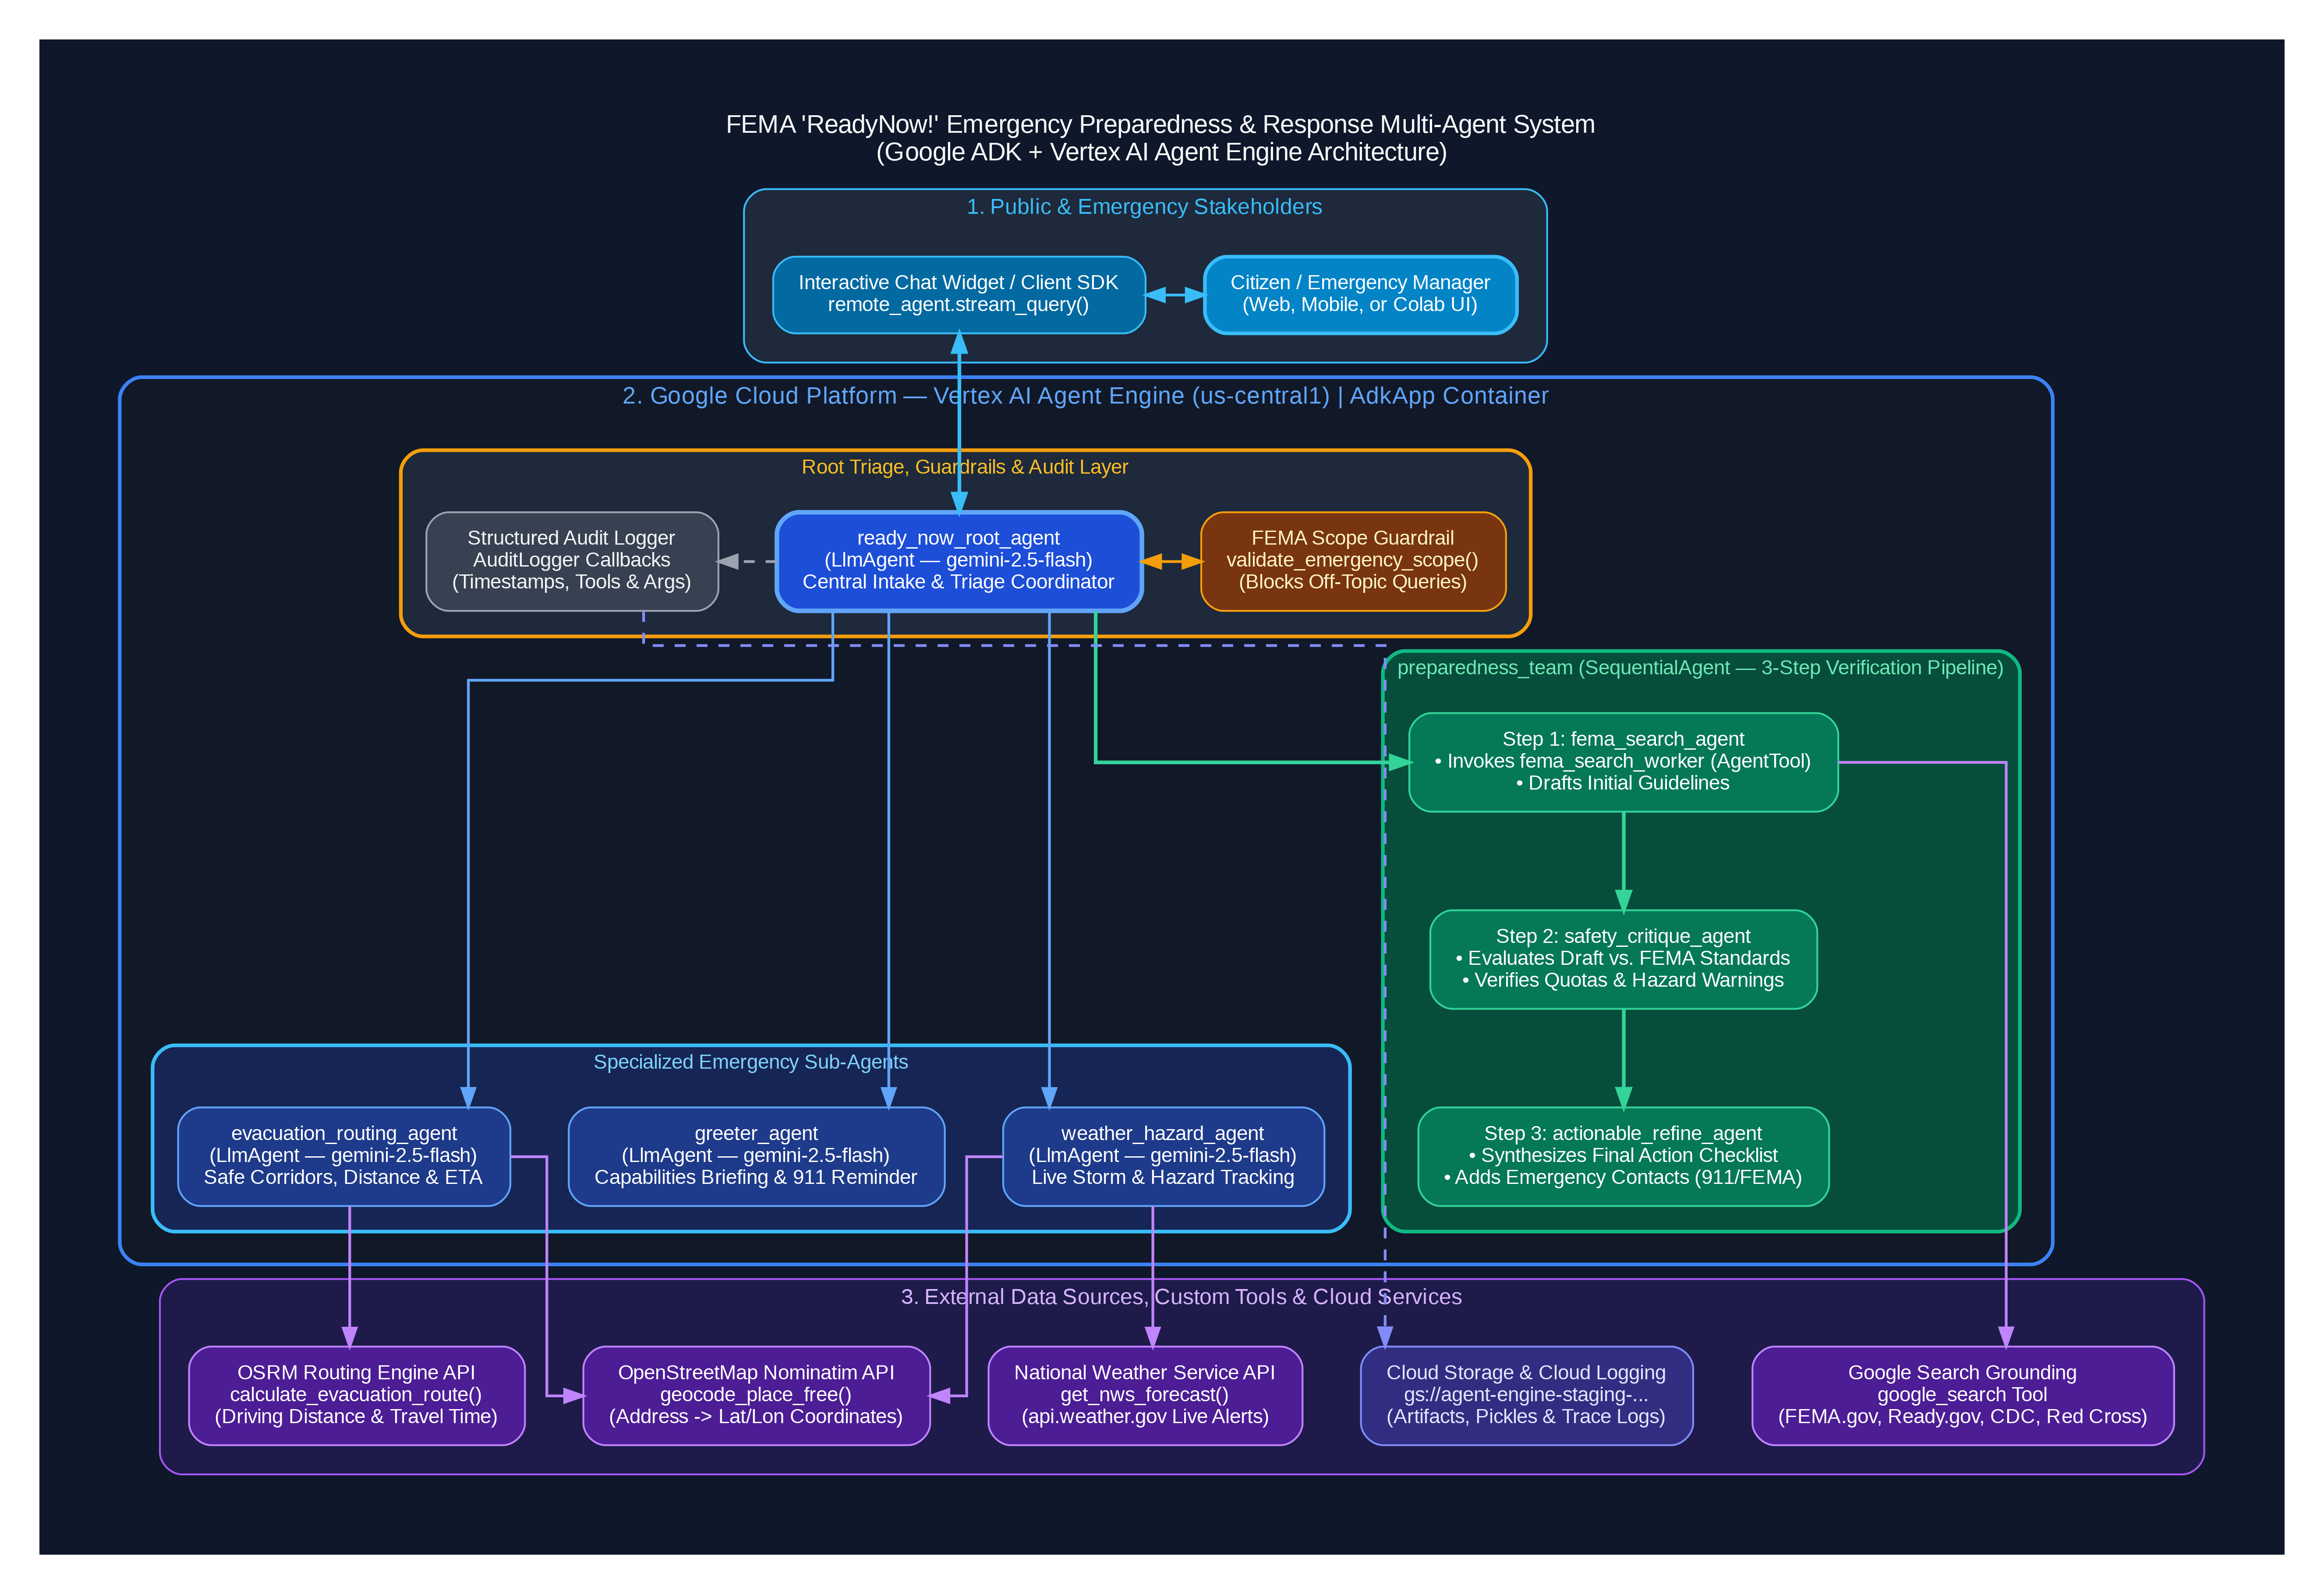

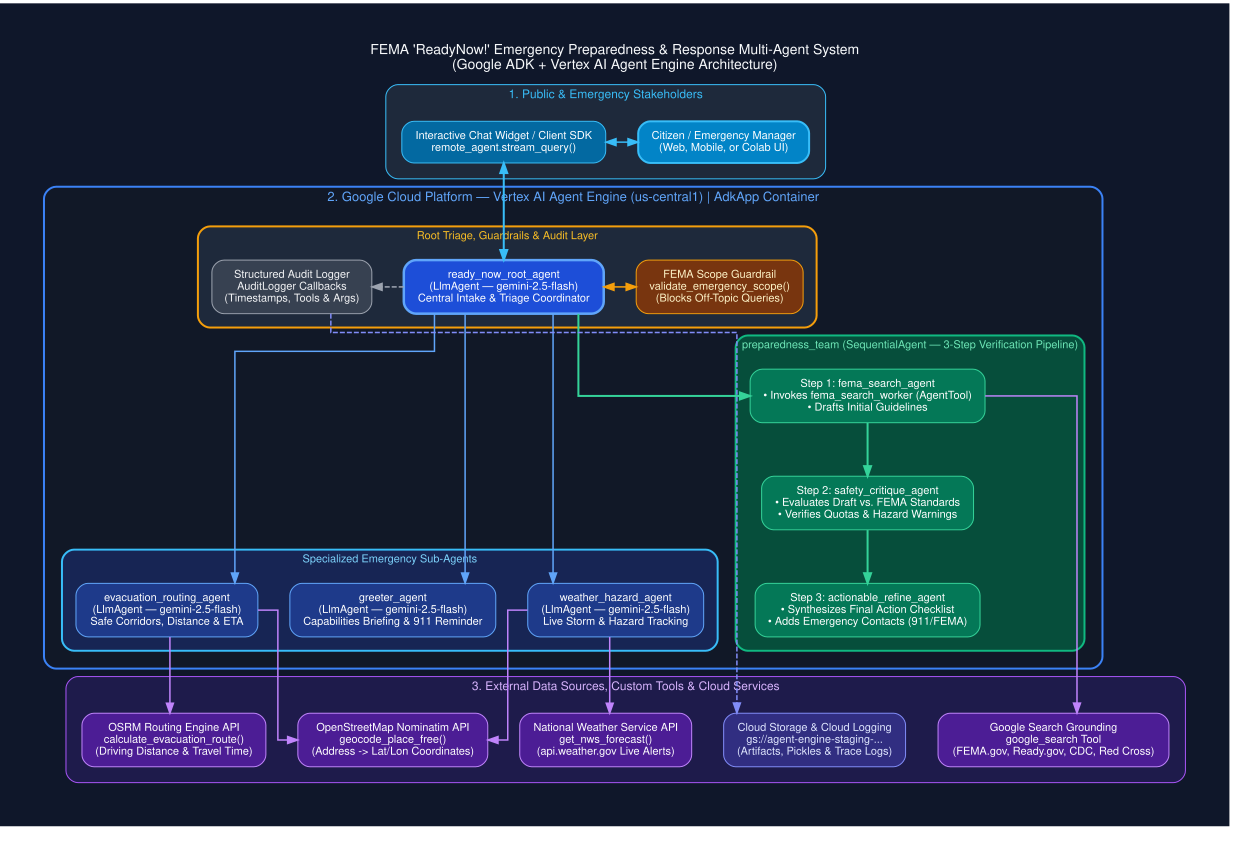

In [51]:
# ============================================================
# Generate & Download High-Resolution SVG & PNG Architecture Diagram
# Fixes SVG viewBox clipping by keeping native 72pt coordinates for SVG
# ============================================================
import base64
import copy
import graphviz
from IPython.display import HTML, Image, SVG, display

dot = graphviz.Digraph(
    name="FEMA_ReadyNow_Architecture",
    comment="FEMA ReadyNow! Multi-Agent System Architecture",
)

# Global graph attributes (DO NOT set dpi here so SVG viewBox stays 1:1 unclipped)
dot.attr(
    rankdir="TB",
    splines="ortho",
    nodesep="0.45",
    ranksep="0.75",
    newrank="true",
    fontname="Helvetica,Arial,sans-serif",
    fontsize="14",
    bgcolor="#0f172a",
    fontcolor="#f8fafc",
    pad="0.5",
    margin="0.3",
    label="FEMA 'ReadyNow!' Emergency Preparedness & Response Multi-Agent System\n(Google ADK + Vertex AI Agent Engine Architecture)",
    labelloc="t",
)

dot.attr(
    "node",
    fontname="Helvetica,Arial,sans-serif",
    fontsize="11",
    shape="rect",
    style="filled,rounded",
    margin="0.2,0.12",
)
dot.attr(
    "edge",
    fontname="Helvetica,Arial,sans-serif",
    fontsize="10",
    color="#94a3b8",
    fontcolor="#cbd5e1",
    penwidth="1.5",
)

# ------------------------------------------------------------
# 1. Public & Emergency Stakeholders Layer (Top)
# ------------------------------------------------------------
with dot.subgraph(name="cluster_user_layer") as c:
    c.attr(
        label="1. Public & Emergency Stakeholders",
        style="filled,rounded",
        color="#38bdf8",
        fillcolor="#1e293b",
        fontcolor="#38bdf8",
        fontsize="12",
        margin="16",
    )
    c.node(
        "User",
        "Citizen / Emergency Manager\n(Web, Mobile, or Colab UI)",
        fillcolor="#0284c7",
        fontcolor="#ffffff",
        color="#38bdf8",
        penwidth="2",
    )
    c.node(
        "StreamAPI",
        "Interactive Chat Widget / Client SDK\nremote_agent.stream_query()",
        fillcolor="#0369a1",
        fontcolor="#ffffff",
        color="#38bdf8",
    )
    with c.subgraph() as r_user:
        r_user.attr(rank="same")
        r_user.node("User")
        r_user.node("StreamAPI")

# ------------------------------------------------------------
# 2. Google Cloud Platform — Vertex AI Agent Engine (Middle)
# ------------------------------------------------------------
with dot.subgraph(name="cluster_vertex_ai") as v:
    v.attr(
        label="2. Google Cloud Platform — Vertex AI Agent Engine (us-central1) | AdkApp Container",
        style="filled,rounded",
        color="#3b82f6",
        fillcolor="#111827",
        fontcolor="#60a5fa",
        fontsize="13",
        penwidth="2",
        margin="18",
    )

    # Root Coordinator & Safety Layer
    with v.subgraph(name="cluster_root_layer") as r:
        r.attr(
            label="Root Triage, Guardrails & Audit Layer",
            style="filled,rounded",
            color="#f59e0b",
            fillcolor="#1e293b",
            fontcolor="#fbbf24",
            fontsize="11",
            margin="14",
        )
        r.node(
            "Guardrail",
            "FEMA Scope Guardrail\nvalidate_emergency_scope()\n(Blocks Off-Topic Queries)",
            fillcolor="#78350f",
            fontcolor="#fef3c7",
            color="#f59e0b",
        )
        r.node(
            "RootAgent",
            "ready_now_root_agent\n(LlmAgent — gemini-2.5-flash)\nCentral Intake & Triage Coordinator",
            fillcolor="#1d4ed8",
            fontcolor="#ffffff",
            color="#60a5fa",
            penwidth="2.5",
        )
        r.node(
            "AuditLogger",
            "Structured Audit Logger\nAuditLogger Callbacks\n(Timestamps, Tools & Args)",
            fillcolor="#374151",
            fontcolor="#f3f4f6",
            color="#9ca3af",
        )
        with r.subgraph() as r_root_same:
            r_root_same.attr(rank="same")
            r_root_same.node("Guardrail")
            r_root_same.node("RootAgent")
            r_root_same.node("AuditLogger")

    # Specialized Sub-Agents
    with v.subgraph(name="cluster_subagents") as s:
        s.attr(
            label="Specialized Emergency Sub-Agents",
            style="filled,rounded",
            color="#38bdf8",
            fillcolor="#172554",
            fontcolor="#7dd3fc",
            fontsize="11",
            margin="14",
        )
        s.node(
            "GreeterAgent",
            "greeter_agent\n(LlmAgent — gemini-2.5-flash)\nCapabilities Briefing & 911 Reminder",
            fillcolor="#1e3a8a",
            fontcolor="#ffffff",
            color="#60a5fa",
        )
        s.node(
            "WeatherAgent",
            "weather_hazard_agent\n(LlmAgent — gemini-2.5-flash)\nLive Storm & Hazard Tracking",
            fillcolor="#1e3a8a",
            fontcolor="#ffffff",
            color="#60a5fa",
        )
        s.node(
            "EvacAgent",
            "evacuation_routing_agent\n(LlmAgent — gemini-2.5-flash)\nSafe Corridors, Distance & ETA",
            fillcolor="#1e3a8a",
            fontcolor="#ffffff",
            color="#60a5fa",
        )

    # 3-Step Sequential Preparedness Team
    with v.subgraph(name="cluster_preparedness") as p:
        p.attr(
            label="preparedness_team (SequentialAgent — 3-Step Verification Pipeline)",
            style="filled,rounded",
            color="#10b981",
            fillcolor="#064e3b",
            fontcolor="#6ee7b7",
            fontsize="11",
            penwidth="2",
            margin="14",
        )
        p.node(
            "Step1",
            "Step 1: fema_search_agent\n• Invokes fema_search_worker (AgentTool)\n• Drafts Initial Guidelines",
            fillcolor="#047857",
            fontcolor="#ffffff",
            color="#34d399",
        )
        p.node(
            "Step2",
            "Step 2: safety_critique_agent\n• Evaluates Draft vs. FEMA Standards\n• Verifies Quotas & Hazard Warnings",
            fillcolor="#047857",
            fontcolor="#ffffff",
            color="#34d399",
        )
        p.node(
            "Step3",
            "Step 3: actionable_refine_agent\n• Synthesizes Final Action Checklist\n• Adds Emergency Contacts (911/FEMA)",
            fillcolor="#047857",
            fontcolor="#ffffff",
            color="#34d399",
        )

# ------------------------------------------------------------
# 3. External APIs, Custom Tools & Cloud Infrastructure (Directly Below Box 2)
# ------------------------------------------------------------
with dot.subgraph(name="cluster_external") as e:
    e.attr(
        label="3. External Data Sources, Custom Tools & Cloud Services",
        style="filled,rounded",
        color="#a855f7",
        fillcolor="#1e1b4b",
        fontcolor="#d8b4fe",
        fontsize="12",
        margin="16",
    )
    e.node(
        "OSM",
        "OpenStreetMap Nominatim API\ngeocode_place_free()\n(Address -> Lat/Lon Coordinates)",
        fillcolor="#4c1d95",
        fontcolor="#ffffff",
        color="#c084fc",
    )
    e.node(
        "NWS",
        "National Weather Service API\nget_nws_forecast()\n(api.weather.gov Live Alerts)",
        fillcolor="#4c1d95",
        fontcolor="#ffffff",
        color="#c084fc",
    )
    e.node(
        "OSRM",
        "OSRM Routing Engine API\ncalculate_evacuation_route()\n(Driving Distance & Travel Time)",
        fillcolor="#4c1d95",
        fontcolor="#ffffff",
        color="#c084fc",
    )
    e.node(
        "GoogleSearch",
        "Google Search Grounding\ngoogle_search Tool\n(FEMA.gov, Ready.gov, CDC, Red Cross)",
        fillcolor="#4c1d95",
        fontcolor="#ffffff",
        color="#c084fc",
    )
    e.node(
        "GCS_Logs",
        "Cloud Storage & Cloud Logging\ngs://agent-engine-staging-...\n(Artifacts, Pickles & Trace Logs)",
        fillcolor="#312e81",
        fontcolor="#e0e7ff",
        color="#818cf8",
    )
    with e.subgraph() as r_ext_same:
        r_ext_same.attr(rank="same")
        r_ext_same.node("OSM")
        r_ext_same.node("NWS")
        r_ext_same.node("OSRM")
        r_ext_same.node("GoogleSearch")
        r_ext_same.node("GCS_Logs")

# ------------------------------------------------------------
# Connections / Edges
# ------------------------------------------------------------
dot.edge("User", "StreamAPI", dir="both", color="#38bdf8", constraint="false")
dot.edge("StreamAPI", "RootAgent", dir="both", color="#38bdf8", penwidth="2")

# Guardrail & Audit horizontal connections inside Root Layer
dot.edge("Guardrail", "RootAgent", dir="both", color="#f59e0b", constraint="false")
dot.edge("RootAgent", "AuditLogger", style="dashed", color="#9ca3af", constraint="false")

# Delegations from Root Coordinator
dot.edge("RootAgent", "GreeterAgent", color="#60a5fa")
dot.edge("RootAgent", "WeatherAgent", color="#60a5fa")
dot.edge("RootAgent", "EvacAgent", color="#60a5fa")
dot.edge("RootAgent", "Step1", color="#34d399", penwidth="2")

# Sequential Pipeline vertical flow
dot.edge("Step1", "Step2", color="#34d399", penwidth="2")
dot.edge("Step2", "Step3", color="#34d399", penwidth="2")

# Invisible vertical anchors to guarantee Box 3 sits strictly below Box 2's lowest nodes
dot.edge("GreeterAgent", "OSM", style="invis", weight="10")
dot.edge("Step3", "GoogleSearch", style="invis", weight="10")
dot.edge("Step3", "GCS_Logs", style="invis", weight="10")

# Tool calls from Box 2 down into Box 3
dot.edge("WeatherAgent", "OSM", color="#c084fc")
dot.edge("WeatherAgent", "NWS", color="#c084fc")
dot.edge("EvacAgent", "OSM", color="#c084fc")
dot.edge("EvacAgent", "OSRM", color="#c084fc")
dot.edge("Step1", "GoogleSearch", color="#c084fc", constraint="false")
dot.edge("AuditLogger", "GCS_Logs", style="dashed", color="#818cf8", constraint="false")

# 1. Render SVG FIRST at native 72 DPI so viewBox matches 100% of the canvas without clipping
svg_filename = "fema_readynow_architecture.svg"
svg_bytes = dot.pipe(format="svg")
with open(svg_filename, "wb") as f:
    f.write(svg_bytes)

# 2. Render PNG on a separate copy with 300 DPI
png_filename = "fema_readynow_architecture.png"
dot_png = copy.deepcopy(dot)
dot_png.attr(dpi="300")
png_bytes = dot_png.pipe(format="png")
with open(png_filename, "wb") as f:
    f.write(png_bytes)

# Create one-click download buttons via Base64 data URIs
b64_png = base64.b64encode(png_bytes).decode("utf-8")
b64_svg = base64.b64encode(svg_bytes).decode("utf-8")

download_bar_html = f"""
<div style="background-color: #1e293b; border: 1px solid #3b82f6; border-radius: 8px; padding: 16px; margin-bottom: 16px; font-family: sans-serif; color: #f8fafc;">
  <h3 style="margin-top: 0; color: #60a5fa;">📥 Download ReadyNow! Architecture Diagram (Full Unclipped Canvas)</h3>
  <p style="margin-bottom: 12px; font-size: 14px; color: #cbd5e1;">
    Both the SVG viewBox and 300-DPI PNG now capture 100% of all three boxes with full margins:
  </p>
  <a href="data:image/png;base64,{b64_png}" download="{png_filename}"
     style="background-color: #2563eb; color: #ffffff; padding: 10px 18px; text-decoration: none; border-radius: 6px; font-weight: bold; margin-right: 12px; display: inline-block;">
     🖼️ Download High-Res PNG (300 DPI)
  </a>
  <a href="data:image/svg+xml;base64,{b64_svg}" download="{svg_filename}"
     style="background-color: #059669; color: #ffffff; padding: 10px 18px; text-decoration: none; border-radius: 6px; font-weight: bold; display: inline-block;">
     📐 Download Scalable Vector SVG
  </a>
</div>
"""

display(HTML(download_bar_html))
display(SVG(svg_bytes))
